<a href="https://colab.research.google.com/github/vardiansyahnabil/Tugas-Proyek-Integrasi/blob/main/PROYEK_INTEGRASI_KKA_3_ANALISIS_FILM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1. IMPORT LIBRARY
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import ast
import warnings

warnings.filterwarnings('ignore')

# Pengaturan tampilan grafik
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10

print("Semua library berhasil diimport!")

Semua library berhasil diimport!


In [3]:
# Membaca dataset

df = pd.read_csv('archive.csv')

print("Dataset berhasil dimuat!")
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

df.head()
df.info()
df.describe()
df.isnull().sum()

print("Jumlah data duplikat:",
      df.duplicated().sum())

Dataset berhasil dimuat!
Jumlah baris: 250
Jumlah kolom: 28
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   250 non-null    object 
 1   url                  250 non-null    object 
 2   primaryTitle         250 non-null    object 
 3   originalTitle        250 non-null    object 
 4   type                 250 non-null    object 
 5   parentImdbId         0 non-null      float64
 6   description          250 non-null    object 
 7   primaryImage         250 non-null    object 
 8   thumbnails           250 non-null    object 
 9   trailer              244 non-null    object 
 10  contentRating        244 non-null    object 
 11  startYear            250 non-null    int64  
 12  endYear              0 non-null      float64
 13  releaseDate          250 non-null    object 
 14  interests            250 non-n

In [4]:
# 4. DATA CLEANING

# Membuat salinan dataset
df = df.copy()

# Menghapus kolom yang seluruh datanya kosong
kolom_kosong = df.columns[df.isnull().all()].tolist()

df = df.drop(columns=kolom_kosong)

# Menghapus data duplikat jika ada
df = df.drop_duplicates()

# Mengubah tanggal rilis menjadi format datetime
df['releaseDate'] = pd.to_datetime(
    df['releaseDate'],
    errors='coerce'
)

# Mengubah genre dari string menjadi list
df['genres'] = df['genres'].apply(
    lambda x: ast.literal_eval(x)
    if isinstance(x, str) else []
)

print("Pembersihan data selesai!")
print("Kolom yang dihapus:", kolom_kosong)
print("Jumlah baris setelah cleaning:", len(df))

# Mengecek kembali data kosong
print("\nMissing value setelah cleaning:")
print(df.isnull().sum())

Pembersihan data selesai!
Kolom yang dihapus: ['parentImdbId', 'endYear']
Jumlah baris setelah cleaning: 250

Missing value setelah cleaning:
id                      0
url                     0
primaryTitle            0
originalTitle           0
type                    0
description             0
primaryImage            0
thumbnails              0
trailer                 6
contentRating           6
startYear               0
releaseDate             0
interests               0
countriesOfOrigin       0
externalLinks           0
spokenLanguages         0
filmingLocations        0
productionCompanies     0
budget                 22
grossWorldwide          4
genres                  0
isAdult                 0
runtimeMinutes          0
averageRating           0
numVotes                0
metascore              20
dtype: int64


In [6]:
#+ 5. ANALISIS STATISTIK DESKRIPTIF

# Mengambil data yang memiliki pendapatan
data_gross = df.dropna(subset=['grossWorldwide'])

# Statistik pendapatan
total_pendapatan = data_gross['grossWorldwide'].sum()

rata_pendapatan = data_gross['grossWorldwide'].mean()

median_pendapatan = data_gross['grossWorldwide'].median()

# Statistik rating
rata_rating = df['averageRating'].mean()

median_rating = df['averageRating'].median()

# Film dengan pendapatan tertinggi
film_tertinggi = df.loc[
    df['grossWorldwide'].idxmax()
]

# Genre dengan pendapatan terbesar
df_genre = df.explode('genres')

pendapatan_genre = (
    df_genre.groupby('genres')['grossWorldwide']
    .sum()
    .sort_values(ascending=False)
)

print("========== HASIL ANALISIS STATISTIK ==========")

print(f"Total Pendapatan Global : ${total_pendapatan:,.2f}")

print(f"Rata-rata Pendapatan    : ${rata_pendapatan:,.2f}")

print(f"Median Pendapatan       : ${median_pendapatan:,.2f}")

print(f"Rata-rata Rating IMDb   : {rata_rating:.2f}")

print(f"Median Rating IMDb      : {median_rating:.2f}")

print("\nFilm dengan pendapatan tertinggi:")
print(film_tertinggi['primaryTitle'])

print("\nGenre dengan pendapatan tertinggi:")
print(pendapatan_genre.head(1))

========== HASIL ANALISIS STATISTIK ==========
Total Pendapatan Global : $59,675,782,597.00
Rata-rata Pendapatan    : $242,584,482.10
Median Pendapatan       : $65,106,932.50
Rata-rata Rating IMDb   : 8.31
Median Rating IMDb      : 8.20

Film dengan pendapatan tertinggi:
Avengers: Endgame

Genre dengan pendapatan tertinggi:
genres
Adventure    3.502077e+10
Name: grossWorldwide, dtype: float64


**Membuat 5 jenis visualisasi**

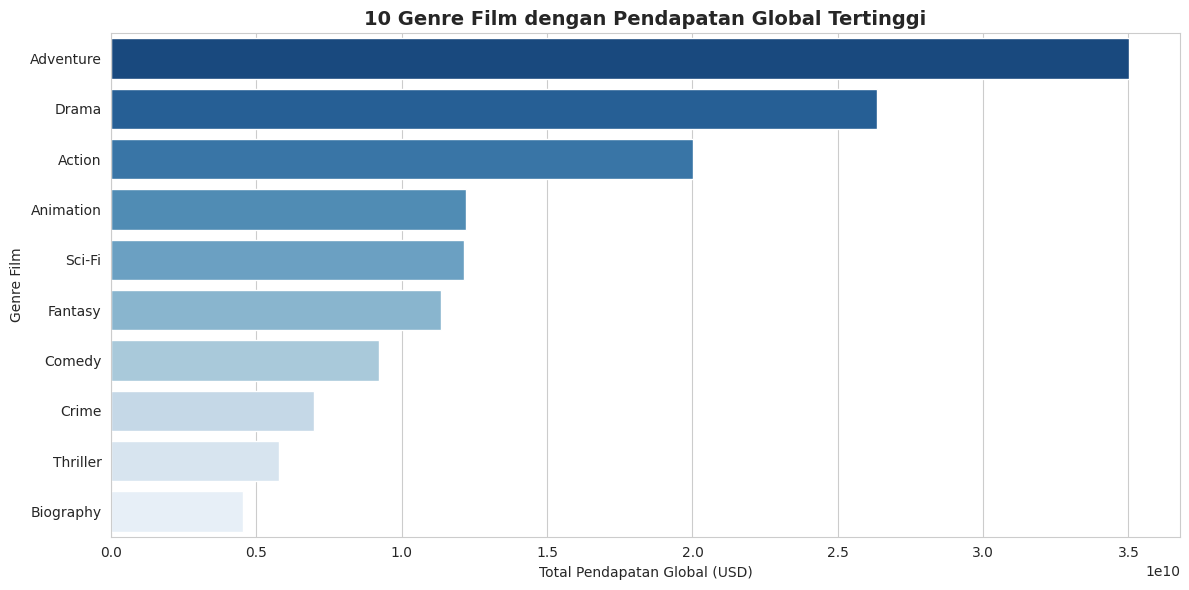

In [7]:
# GRAFIK 1: BAR CHART

plt.figure(figsize=(12, 6))

top_genre = pendapatan_genre.head(10)

sns.barplot(
    x=top_genre.values,
    y=top_genre.index,
    hue=top_genre.index,
    palette='Blues_r',
    legend=False
)

plt.title('10 Genre Film dengan Pendapatan Global Tertinggi',
          fontsize=14, fontweight='bold')

plt.xlabel('Total Pendapatan Global (USD)')
plt.ylabel('Genre Film')

plt.tight_layout()
plt.show()

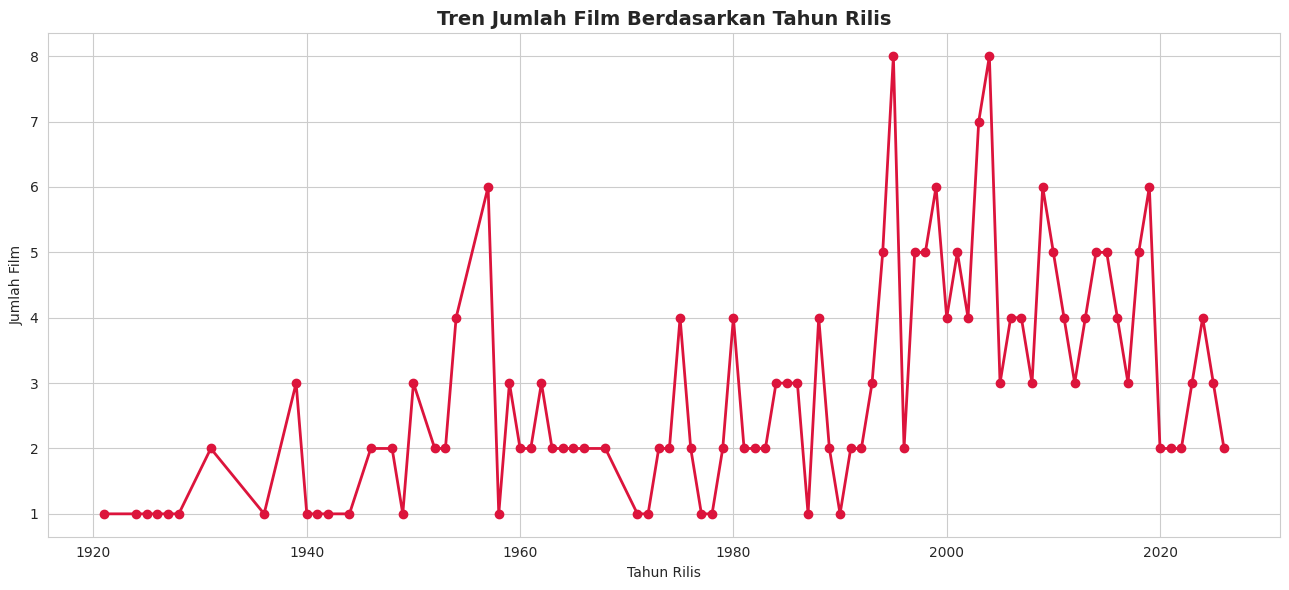

In [8]:
# ==========================================
# GRAFIK 2: LINE CHART
# ==========================================

tren_tahunan = df.groupby('startYear').size()

plt.figure(figsize=(13, 6))

plt.plot(
    tren_tahunan.index,
    tren_tahunan.values,
    marker='o',
    color='crimson',
    linewidth=2
)

plt.title('Tren Jumlah Film Berdasarkan Tahun Rilis',
          fontsize=14, fontweight='bold')

plt.xlabel('Tahun Rilis')
plt.ylabel('Jumlah Film')

plt.grid(True)
plt.tight_layout()
plt.show()

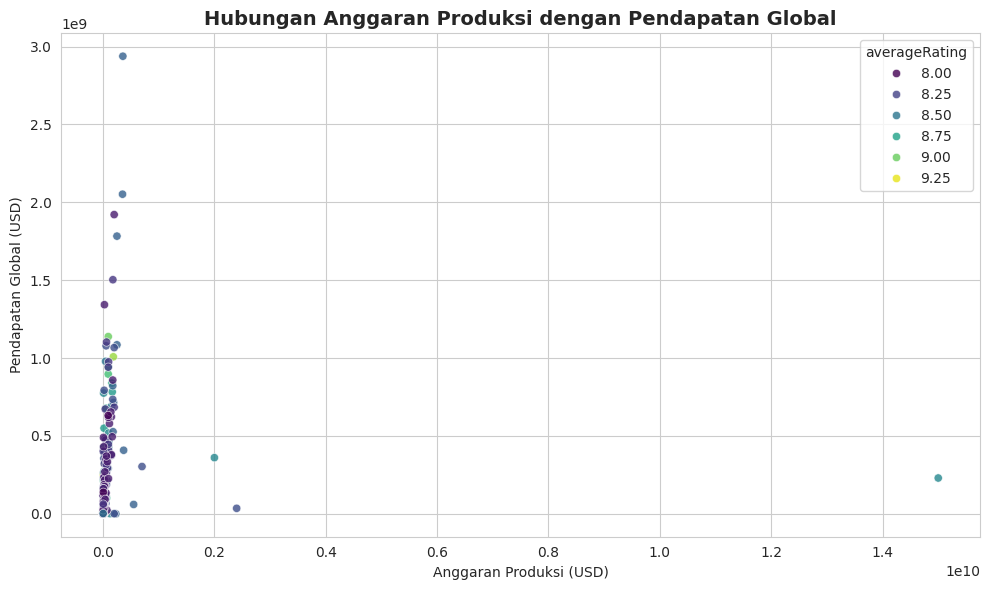

In [9]:
# ==========================================
# GRAFIK 3: SCATTER PLOT
# ==========================================

data_scatter = df.dropna(
    subset=['budget', 'grossWorldwide']
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=data_scatter,
    x='budget',
    y='grossWorldwide',
    hue='averageRating',
    palette='viridis',
    alpha=0.8
)

plt.title('Hubungan Anggaran Produksi dengan Pendapatan Global',
          fontsize=14, fontweight='bold')

plt.xlabel('Anggaran Produksi (USD)')
plt.ylabel('Pendapatan Global (USD)')

plt.tight_layout()
plt.show()

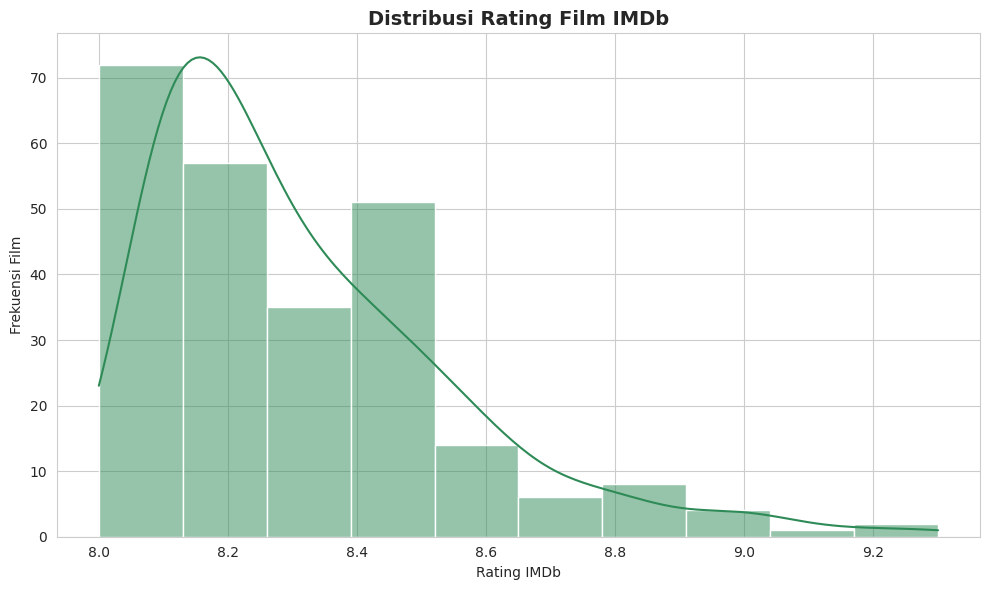

In [10]:
# ==========================================
# GRAFIK 4: HISTOGRAM
# ==========================================

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='averageRating',
    bins=10,
    color='seagreen',
    kde=True
)

plt.title('Distribusi Rating Film IMDb',
          fontsize=14, fontweight='bold')

plt.xlabel('Rating IMDb')
plt.ylabel('Frekuensi Film')

plt.tight_layout()
plt.show()

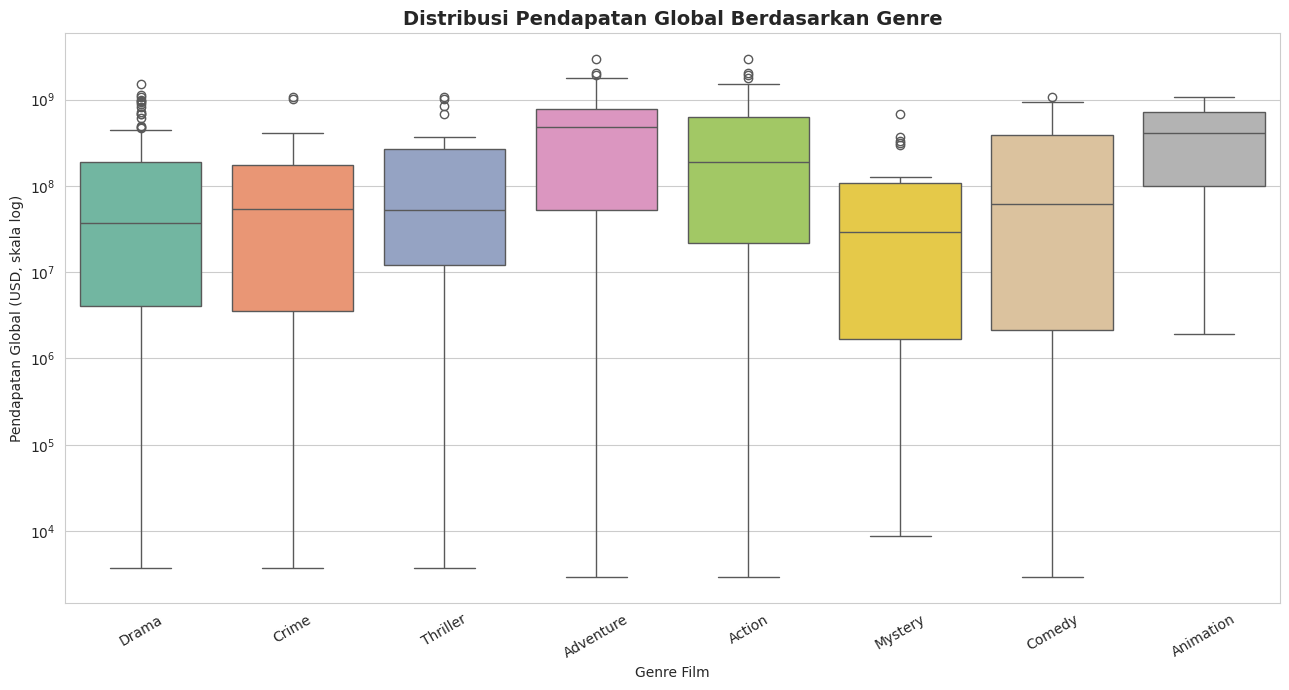

In [11]:
# ==========================================
# GRAFIK 5: BOXPLOT
# ==========================================

# Menghitung genre yang paling sering muncul
genre_populer = (
    df_genre['genres']
    .value_counts()
    .head(8)
    .index
)

data_boxplot = df_genre[
    df_genre['genres'].isin(genre_populer)
].dropna(subset=['grossWorldwide'])

plt.figure(figsize=(13, 7))

sns.boxplot(
    data=data_boxplot,
    x='genres',
    y='grossWorldwide',
    hue='genres',
    palette='Set2',
    legend=False
)

plt.yscale('log')

plt.title('Distribusi Pendapatan Global Berdasarkan Genre',
          fontsize=14, fontweight='bold')

plt.xlabel('Genre Film')
plt.ylabel('Pendapatan Global (USD, skala log)')

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [12]:
# ==========================================
# 7. DETEKSI OUTLIER DENGAN IQR
# ==========================================

data = df['grossWorldwide'].dropna()

# Menghitung kuartil
Q1 = data.quantile(0.25)
Q2 = data.quantile(0.50)
Q3 = data.quantile(0.75)

# Menghitung IQR
IQR = Q3 - Q1

# Batas outlier
batas_bawah = Q1 - (1.5 * IQR)
batas_atas = Q3 + (1.5 * IQR)

# Mengambil data outlier
outlier = df[
    (df['grossWorldwide'] < batas_bawah) |
    (df['grossWorldwide'] > batas_atas)
]

print("========== HASIL DETEKSI OUTLIER ==========")

print("Q1:", Q1)
print("Median:", Q2)
print("Q3:", Q3)
print("IQR:", IQR)

print("Batas bawah:", batas_bawah)
print("Batas atas:", batas_atas)

print("\nJumlah outlier:", len(outlier))

print("\nDaftar film yang terdeteksi sebagai outlier:")

display(
    outlier[
        ['primaryTitle', 'genres',
         'budget', 'grossWorldwide', 'averageRating']
    ].sort_values(
        by='grossWorldwide',
        ascending=False
    )
)

========== HASIL DETEKSI OUTLIER ==========
Q1: 10241029.25
Median: 65106932.5
Q3: 333335522.75
IQR: 323094493.5
Batas bawah: -474400711.0
Batas atas: 817977263.0

Jumlah outlier: 20

Daftar film yang terdeteksi sebagai outlier:


,primaryTitle,genres,budget,grossWorldwide,averageRating
73,Avengers: Endgame,"[Action, Adventure, Sci-Fi]",356000000.0,2.938420e+09,8.4
58,Avengers: Infinity War,"[Action, Adventure, Sci-Fi]",350000000.0,2.052415e+09,8.4
207,Spider-Man: No Way Home,"[Action, Adventure, Fantasy]",200000000.0,1.921426e+09,8.1
62,The Odyssey,"[Action, Adventure, Fantasy]",250000000.0,1.783213e+09,8.4
152,Top Gun: Maverick,"[Action, Drama]",177000000.0,1.503260e+09,8.2
178,Harry Potter and the Deathly Hallows: Part 2,"[Adventure, Family, Fantasy]",25000000.0,1.342946e+09,8.1
4,The Lord of the Rings: The Return of the King,"[Adventure, Drama, Fantasy]",94000000.0,1.138064e+09,9.0
135,Jurassic Park,"[Adventure, Sci-Fi]",63000000.0,1.103137e+09,8.2
77,The Dark Knight Rises,"[Crime, Thriller]",250000000.0,1.085430e+09,8.4
91,Joker,[Drama],55000000.0,1.078959e+09,8.3


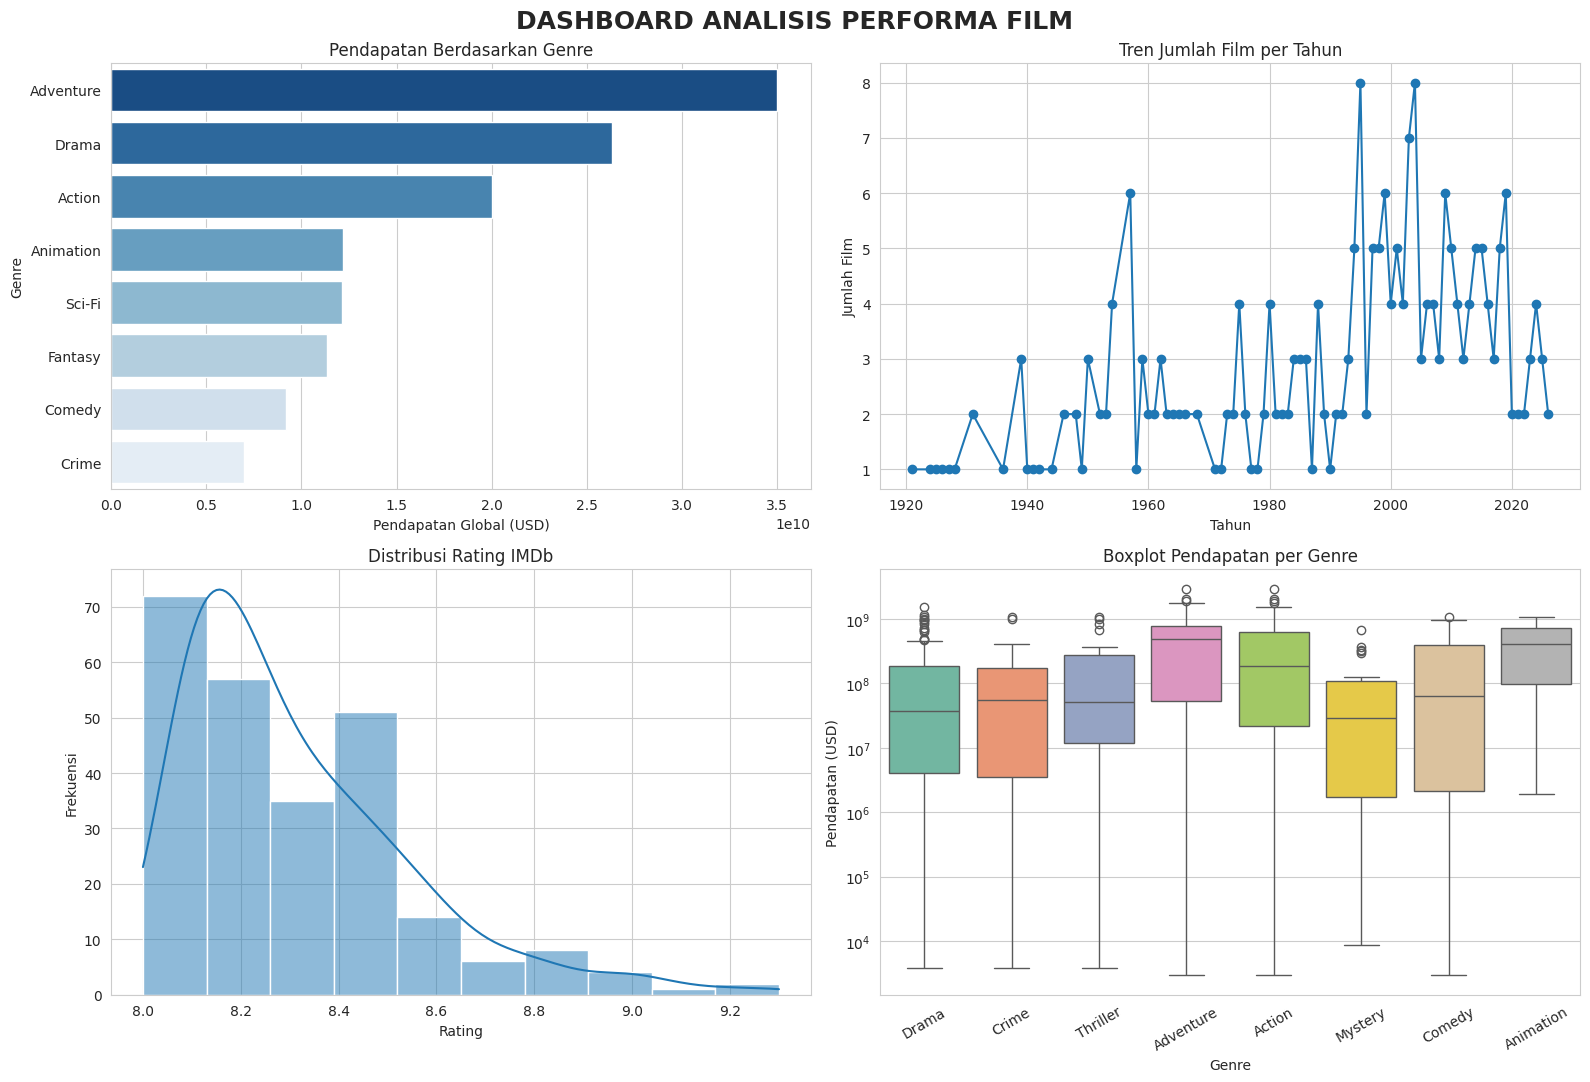

In [14]:
# ==========================================
# 8. DASHBOARD ANALISIS FILM
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Grafik 1: Pendapatan per genre
sns.barplot(
    x=pendapatan_genre.head(8).values,
    y=pendapatan_genre.head(8).index,
    hue=pendapatan_genre.head(8).index,
    palette='Blues_r',
    legend=False,
    ax=axes[0, 0]
)

axes[0, 0].set_title('Pendapatan Berdasarkan Genre')
axes[0, 0].set_xlabel('Pendapatan Global (USD)')
axes[0, 0].set_ylabel('Genre')

# Grafik 2: Tren jumlah film
axes[0, 1].plot(
    tren_tahunan.index,
    tren_tahunan.values,
    marker='o'
)

axes[0, 1].set_title('Tren Jumlah Film per Tahun')
axes[0, 1].set_xlabel('Tahun')
axes[0, 1].set_ylabel('Jumlah Film')

# Grafik 3: Distribusi rating
sns.histplot(
    data=df,
    x='averageRating',
    bins=10,
    kde=True,
    ax=axes[1, 0]
)

axes[1, 0].set_title('Distribusi Rating IMDb')
axes[1, 0].set_xlabel('Rating')
axes[1, 0].set_ylabel('Frekuensi')

# Grafik 4: Boxplot pendapatan
sns.boxplot(
    data=data_boxplot,
    x='genres',
    y='grossWorldwide',
    hue='genres',
    palette='Set2',
    legend=False,
    ax=axes[1, 1]
)

axes[1, 1].set_yscale('log')
axes[1, 1].set_title('Boxplot Pendapatan per Genre')
axes[1, 1].set_xlabel('Genre')
axes[1, 1].set_ylabel('Pendapatan (USD)')
axes[1, 1].tick_params(axis='x', rotation=30)

plt.suptitle(
    'DASHBOARD ANALISIS PERFORMA FILM',
    fontsize=18,
    fontweight='bold'
)

plt.tight_layout()
plt.savefig(
    'dashboard_analisis_film.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

# LAPORAN ANALISIS DATA PERFORMA FILM

## 1. Ringkasan Statistik

Dataset yang digunakan berisi 250 data film dengan 28 kolom informasi. Berdasarkan hasil analisis, total pendapatan global film adalah sebesar USD 59.675.782.597, dengan rata-rata pendapatan sebesar USD 242.584.482 dan median sebesar USD 65.106.932,50. Rata-rata rating IMDb adalah 8,31 dari skala 10.

Film dengan pendapatan global tertinggi adalah Avengers: Endgame.

## 2. Temuan Utama (Insight)

Berdasarkan visualisasi Bar Chart, genre dengan akumulasi pendapatan terbesar adalah Adventure. Hasil ini menunjukkan bahwa genre Adventure memiliki kontribusi pendapatan yang tinggi dalam dataset yang dianalisis.

Berdasarkan Line Chart, perkembangan jumlah film berdasarkan tahun rilis menunjukkan pola [isi berdasarkan grafik]. Sementara itu, Scatter Plot digunakan untuk mengamati hubungan antara anggaran produksi dan pendapatan global.

Histogram menunjukkan bahwa distribusi rating film cenderung [isi berdasarkan grafik]. Boxplot memperlihatkan variasi pendapatan pada masing-masing genre.

## 3. Potensi Outlier

Berdasarkan metode Interquartile Range (IQR), ditemukan [jumlah] film yang memiliki pendapatan di luar batas normal statistik. Film-film tersebut memiliki pendapatan jauh lebih tinggi dibandingkan mayoritas film lainnya. Kemungkinan penyebabnya adalah popularitas film, skala distribusi, dan tingginya minat penonton.

## 4. Rekomendasi Bisnis

Berdasarkan hasil analisis, perusahaan dapat mempertimbangkan genre dengan pendapatan tinggi sebagai salah satu referensi dalam menentukan strategi investasi dan promosi film. Perusahaan juga perlu memperhatikan hubungan antara anggaran produksi dan pendapatan agar keputusan investasi lebih terukur.

Selain itu, rating dan jumlah suara penonton dapat digunakan sebagai indikator tambahan untuk mengevaluasi penerimaan film. Perusahaan sebaiknya tidak hanya berfokus pada pendapatan, tetapi juga mempertimbangkan kualitas dan respons penonton terhadap film yang diproduksi.

In [ ]:
# ==========================================
# 10. EXPORT HASIL ANALISIS
# ==========================================

# Simpan dataset yang telah dibersihkan
df.to_csv(
    'dataset_film_clean.csv',
    index=False
)

# Simpan data outlier
outlier.to_csv(
    'data_outlier_film.csv',
    index=False
)

# Simpan hasil statistik
statistik = pd.DataFrame({
    'Indikator': [
        'Total Pendapatan',
        'Rata-rata Pendapatan',
        'Median Pendapatan',
        'Rata-rata Rating',
        'Median Rating'
    ],
    'Nilai': [
        total_pendapatan,
        rata_pendapatan,
        median_pendapatan,
        rata_rating,
        median_rating
    ]
})

statistik.to_csv(
    'hasil_statistik.csv',
    index=False
)

print("Semua hasil analisis berhasil disimpan!")